In [1]:
#imports
import numpy as np
import pandas as pd
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

from matplotlib.ticker import AutoMinorLocator, MultipleLocator

In [2]:

info = (
    ["V392 Per", 3, 5.6, 5.226, .262, 32, 81.9, 4100, 1.1*10e-7, 3.2,  0.6,  -0.4],
    ["V407 Cyg", 5.9, 7.1, 17.77, 0.901,  102.6, 43*365.25*24, 3200, 2.9*10e-7, 4.52, 2.5, -1.8],
    ["V1535 Sco", 13.9, 9.7, 4.123, .208 , 2.663, 39.6*24, 4700, 2.2*10e-7, 4.6, 0.9,  -0.6],
    ["V1534 Sco", 5.6, 11.6, 13.3, .665 ,14.65, 520*24, 4100, 5.8*10e-7, 8.61, 1.7,  -1.1],
    ['V723 Cas', 263, 7.1, 13.5, 1.125 , 1697, 16.6, 1750, 2.4*10e-7, 4.7,  1.0,  -0.7],
    ['V5589 Sgr', 4.5, 9.06, 3.423, .173, 62.3, 38.2, 4800, 3.2*10e-7, 7.5,  0.9,  -1.1],
    ['RS Oph', 2.77,4.5, 67.597, 3.381, 9.99, 453.6*24,3700, 6.1*10e-8, 2.71, 0.2,  -0.1],
    ['U Sco', 1, 7.5, 0.115, 0.029, 32.53, 29.5, 5000, 3.7*10e-7, 7.5, 2, -2],
    ['V745 Sco',6.2,9.4,8.93,0.45,25.6, 136.5*24,4450, 4.9*10e-7, 8.2, 1.4, -1.3],
    ['V3890 Sgr',6.4,7.2,51.11,2.56,11.2,747.6*24,4200, 4.2*10e-7, 6.04,1.3,-1.1],
    ['V1370 Aql',15,7.7,20.2,2.46,73.5,1.9581*24,2200,8.2*10e-8,2.2,  1.0,  -0.5]

)

df = pd.DataFrame(info, columns = ['Nova (names)', 't2 visual (when the optical declined by 2 mag)', 'Vpeak (optical peak apparent mag)', 
                                   'flux max (Smax)','Smax error', 'day when flux max (tmax)', 'orbital period (hours)', 'velocity (km/s)',
                                   'mdot (msun/yr)', 'Distance (kpc)', '+err','-err'])


df

,Nova (names),t2 visual (when the optical declined by 2 mag),Vpeak (optical peak apparent mag),flux max (Smax),Smax error,day when flux max (tmax),orbital period (hours),velocity (km/s),mdot (msun/yr),Distance (kpc),+err,-err
0,V392 Per,3.00,5.60,5.226,0.262,32.000,81.9000,4100,1.100000e-06,3.20,0.6,-0.4
1,V407 Cyg,5.90,7.10,17.770,0.901,102.600,376938.0000,3200,2.900000e-06,4.52,2.5,-1.8
2,V1535 Sco,13.90,9.70,4.123,0.208,2.663,950.4000,4700,2.200000e-06,4.60,0.9,-0.6
3,V1534 Sco,5.60,11.60,13.300,0.665,14.650,12480.0000,4100,5.800000e-06,8.61,1.7,-1.1
4,V723 Cas,263.00,7.10,13.500,1.125,1697.000,16.6000,1750,2.400000e-06,4.70,1.0,-0.7
5,V5589 Sgr,4.50,9.06,3.423,0.173,62.300,38.2000,4800,3.200000e-06,7.50,0.9,-1.1
6,RS Oph,2.77,4.50,67.597,3.381,9.990,10886.4000,3700,6.100000e-07,2.71,0.2,-0.1
7,U Sco,1.00,7.50,0.115,0.029,32.530,29.5000,5000,3.700000e-06,7.50,2.0,-2.0
8,V745 Sco,6.20,9.40,8.930,0.450,25.600,3276.0000,4450,4.900000e-06,8.20,1.4,-1.3
9,V3890 Sgr,6.40,7.20,51.110,2.560,11.200,17942.4000,4200,4.200000e-06,6.04,1.3,-1.1


## t2 vs tmax

- Plot: t2 (time to decline by 2 mag in the optical) vs tmax (time to radio peak)
- Scale: log log for both axis
- Note: 5GHz frequency band


In [12]:
t2 = df['t2 visual (when the optical declined by 2 mag)']

tmax = df['day when flux max (tmax)']

names = df["Nova (names)"]

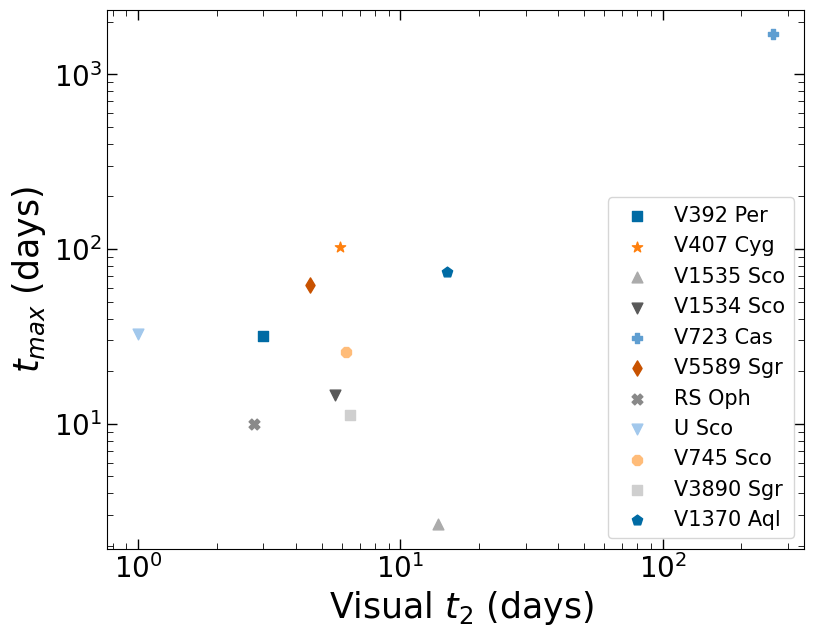

In [13]:
plt.style.use('tableau-colorblind10')
#plt.style.use('dark_background')
fig, ax = plt.subplots()
fig.set_size_inches(9,7)



ax.scatter(t2[0], tmax[0], label="V392 Per", marker='s', s=60)

ax.scatter(t2[1], tmax[1], label="V407 Cyg", marker='*', s=60)
            
ax.scatter(t2[2],tmax[2], label="V1535 Sco", marker='^', s=60)
            
ax.scatter(t2[3],tmax[3],label="V1534 Sco", marker='v', s=60)

ax.scatter(t2[4], tmax[4],label="V723 Cas", marker='P', s=60)

ax.scatter(t2[5], tmax[5], label="V5589 Sgr", marker='d', s=60)

ax.scatter(t2[6], tmax[6], label="RS Oph",marker='X', s=60)

ax.scatter(t2[7], tmax[7], label="U Sco", marker='v', s=60)

ax.scatter(t2[8], tmax[8], label="V745 Sco",marker='8', s=60)

ax.scatter(t2[9], tmax[9], label="V3890 Sgr",marker='s', s=60)

ax.scatter(t2[10], tmax[10],label="V1370 Aql",marker='p', s=60)

#ax.plot(t2, fit_model_weights(t2), linestyle=":")

ax.set_xscale('log')
ax.set_xticks([1,10,100], labels = [r'$10^{0}$',r'$10^1$', r'$10^2$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([ 10, 100, 1000], labels = [r'$10^1$', r'$10^2$', r'$10^3$'], fontsize = 20)

ax.set_xlabel(r" Visual $ t_{2} $ (days)", fontsize=25)
ax.set_ylabel(r"$ t_{max} $ (days)", fontsize=25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)


plt.legend(fontsize = 15)
plt.show()
fig.savefig("tmax_t2.png", dpi=300);

## Vpeak vs Smax

- Plot: peak V-band magnitude vs peak radio flux density
- Scale: log on y-axis only
- Note: 5 GHz frequency


In [18]:
novae = pd.read_csv('/Users/isabellamolina/Downloads/NOVAE_CHAR.csv', header = 0)


In [19]:
Extinction = novae['EB-V']
Extinc_err = novae['EB_err']

AV = 3.1 * Extinction

New_Vpeak = novae['V_p'] - AV

np.array(New_Vpeak)

array([4.36 , 5.24 , 6.6  , 8.19 , 5.55 , 6.58 , 2.33 , 7.19 , 6.3  ,
       4.41 , 6.429])

In [20]:
AV1 = 3.1 * 0
AV2 = 3.1 * 0.41

New_V1 = novae['V_p'][10] - AV1
New_V2 = novae['V_p'][10] - AV2


In [21]:
New_VV = (New_V1 + New_V2)/2

In [22]:
new_err = New_V1 - New_VV

In [23]:

Smax = novae['S_m']
Smax_err = novae["S_e"]

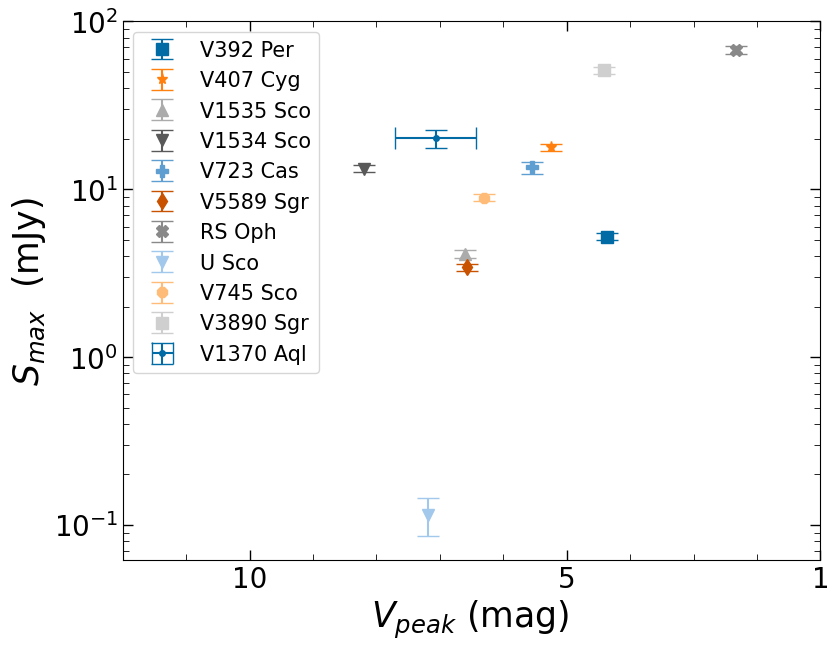

In [24]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.errorbar(New_Vpeak[0], Smax[0], yerr=Smax_err[0], label="V392 Per", fmt='s',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[1], Smax[1], yerr=Smax_err[1],label="V407 Cyg", fmt='*',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[2], Smax[2], yerr=Smax_err[2], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[3], Smax[3], yerr=Smax_err[3], fmt='v', label="V1534 Sco", capsize=8, markersize=8)            

ax.errorbar(New_Vpeak[4], Smax[4], yerr=Smax_err[4], label="V723 Cas", fmt='P',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[5], Smax[5], yerr=Smax_err[5], label="V5589 Sgr", fmt='d', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[6], Smax[6], yerr=Smax_err[6], label="RS Oph", fmt='X', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[7], Smax[7], yerr=Smax_err[7], fmt='v', label="U Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[8], Smax[8], yerr=Smax_err[8], label="V745 Sco", fmt='8', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[9], Smax[9], yerr=Smax_err[9], label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.errorbar(New_VV, Smax[10], xerr=new_err, yerr=Smax_err[10], label="V1370 Aql",fmt='.',capsize=8, markersize=8)

ax.set_xticks([10,5,1], labels = ['10', '5', '1'], fontsize = 20)
ax.invert_xaxis()

ax.set_xlim([12,1])


ax.set_yscale('log')
ax.set_yticks([0.1,1, 10, 100], labels = [r'$10^{-1}$',r'$10^0$', r'$10^1$', r'$10^2$'], fontsize = 20)

ax.set_xlabel(r"$ V_{peak} $ (mag) ", fontsize=25)
ax.set_ylabel(r"$ S_{max} $  (mJy)", fontsize=25)


ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.xaxis.set_minor_locator(AutoMinorLocator(4))

plt.legend(fontsize = 15)
plt.show()
fig.savefig("Extinction_Corrected", dpi=300);



## Orbital period vs Radio Luminosity 
- Plots: Orbital period in hours vs radio luminosity
- Scale: log-log
- Notes:

In [25]:
#Convert distance from kpc to cm 
D = df['Distance (kpc)'] * 3.0857e+21
p_err = df['+err'] * 3.0857e+21 
n_err =  (df['-err'] * -3.0857e+21)

orbital_period = df["orbital period (hours)"]

In [26]:
#Convert from mJy to Jy then to erg/s/cm/Hz: 1 Jy to 10−23 erg⋅s−1⋅cm−2⋅Hz−1
Smax = df['flux max (Smax)'] * 0.001 * (10**(-23))
Smax_err = df['Smax error'] * 0.001 * (10**(-23))

In [27]:
#Radio luminosity: L = 4 pi d^2 F 

Lum = 4 * np.pi * (D**2) * Smax

Lum_err = np.sqrt((8*np.pi*D*Smax)**2 * (p_err**2) + (4*np.pi*D**2)**2*(Smax_err**2))
Lum_nerr = np.sqrt((8*np.pi*D*Smax)**2 * (n_err**2) + (4*np.pi*D**2)**2*(Smax_err**2))

In [28]:
#[lower, upper]
er1 =  np.array([1.632631e+19, 2.422505e+19])
er2 = np.array([3.466761e+20, 4.810263e+20])
er3 = np.array([2.773591e+19, 4.118514e+19])
er4 = np.array([3.071527e+20, 4.695747e+20])
er5 = np.array([1.103672e+20, 1.547216e+20])
er6 = np.array([6.857417e+19, 5.650413e+19])
er7 = np.array([5.295647e+19, 9.257170e+19])
er8 = np.array([4.566146e+18, 4.566146e+18])
er9 = np.array([2.306601e+20, 2.479814e+20])
er10 = np.array([8.202585e+20, 9.668380e+20])
er11 = np.array([5.504837e+19, 1.072960e+20])


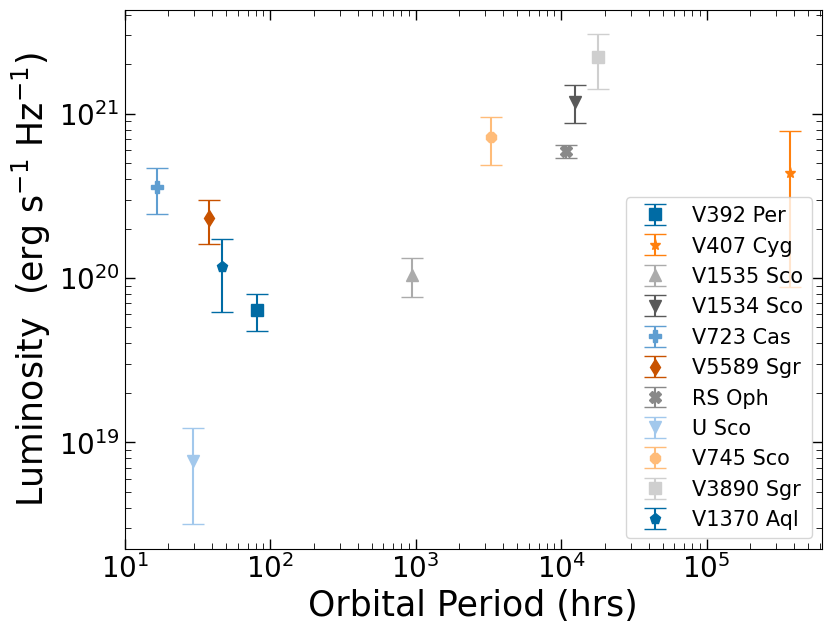

In [30]:

fig, ax = plt.subplots()
fig.set_size_inches(9,7)

plt.style.use('tableau-colorblind10')
#plt.style.use('dark_background')


ax.errorbar(orbital_period[0], Lum[0], yerr=er1[0], label="V392 Per", fmt='s', capsize=8, markersize=8)

ax.errorbar(orbital_period[1], Lum[1], yerr=er2[0], label="V407 Cyg", fmt='*', capsize=8, markersize=8)

ax.errorbar(orbital_period[2], Lum[2], yerr=er3[0], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.errorbar(orbital_period[3], Lum[3], yerr=er4[0], fmt='v', label="V1534 Sco", capsize=8, markersize=8)            

ax.errorbar(orbital_period[4], Lum[4], yerr=er5[0], label="V723 Cas", fmt='P', capsize=8, markersize=8)

ax.errorbar(orbital_period[5], Lum[5], yerr=er6[0], label="V5589 Sgr", fmt='d', capsize=8, markersize=8)

ax.errorbar(orbital_period[6], Lum[6], yerr=er7[0], label="RS Oph",fmt='X', capsize=8, markersize=8)

ax.errorbar(orbital_period[7], Lum[7], yerr=er8[0], fmt='v', label="U Sco", capsize=8, markersize=8)

ax.errorbar(orbital_period[8], Lum[8], yerr=er9[0], label="V745 Sco", fmt='8', capsize=8, markersize=8)

ax.errorbar(orbital_period[9], Lum[9], yerr=er10[0], label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.errorbar(orbital_period[10], Lum[10],  yerr=er11[0], label="V1370 Aql", fmt='p', capsize=8, markersize=8)

ax.set_xscale('log')
ax.set_xticks([10, 100, 1000, 10000, 100000], labels = [r'$10^1$', r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([1e19, 1e20, 1e21], labels = [r'$10^{19}$',r'$10^{20}$', r'$10^{21}$'], fontsize = 20)

ax.set_xlabel(" Orbital Period (hrs) ", fontsize=25)
ax.set_ylabel(r"Luminosity  (erg s$^{-1}$ Hz$^{-1}$)", fontsize=25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)



plt.legend(loc='best',fontsize = 15)
plt.show()
fig.savefig("Orbital Period vs Radio Lum", dpi=300);

## Velocity vs Tmax
- Plot: velocity in km/s vs time to max radio flux
- Scale: log-log
- Notes: 

In [31]:
velocity = df['velocity (km/s)']

tmax = df['day when flux max (tmax)']

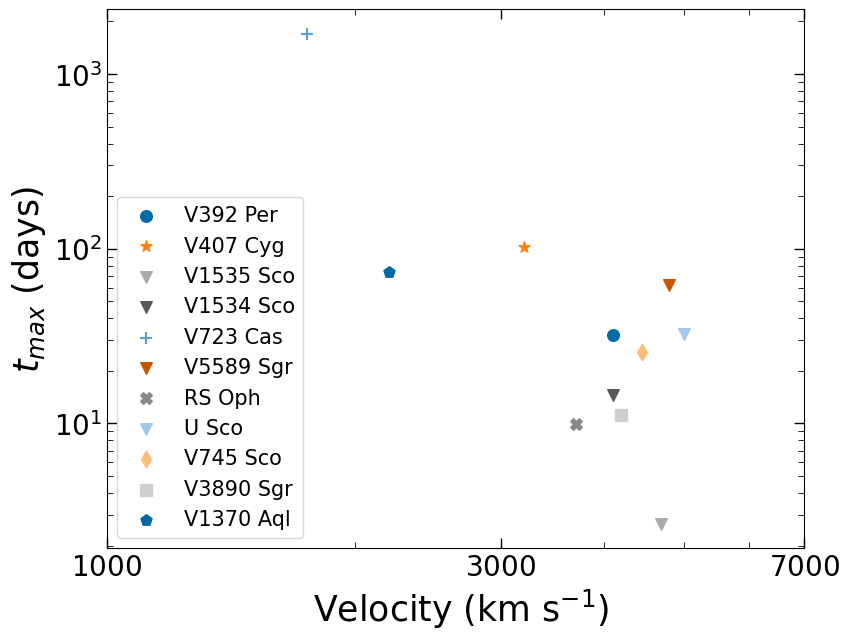

In [35]:
plt.style.use('tableau-colorblind10')
#plt.style.use('dark_background')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.scatter(velocity[0], tmax[0], marker = 'o', s=70, label="V392 Per")

ax.scatter(velocity[1], tmax[1], marker = '*', s=70, label="V407 Cyg")
            
ax.scatter(velocity[2],tmax[2], marker = 'v', s=70, label="V1535 Sco")
            
ax.scatter(velocity[3],tmax[3], marker = 'v', s=70, label="V1534 Sco")

ax.scatter(velocity[4], tmax[4], marker = '+', s=70, label="V723 Cas")

ax.scatter(velocity[5], tmax[5], marker = 'v', s=70, label="V5589 Sgr")

ax.scatter(velocity[6], tmax[6], marker = 'X', s=70, label="RS Oph")

ax.scatter(velocity[7], tmax[7], marker = 'v', s=70, label="U Sco")

ax.scatter(velocity[8], tmax[8], marker = 'd', s=70, label="V745 Sco")

ax.scatter(velocity[9], tmax[9], marker = 's', s=70, label="V3890 Sgr")

ax.scatter(velocity[10], tmax[10], marker = 'p', s=70, label="V1370 Aql")


ax.set_xscale('log')
ax.set_xticks([1000,3000, 7000], labels = [ r'$1000$',r'$3000$' ,r'$7000$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([ 10, 100, 1000], labels = [r'$10^1$', r'$10^2$', r'$10^3$'], fontsize = 20)

ax.set_xlabel(r" Velocity (km s$^{-1})$", fontsize=25)
ax.set_ylabel(r"$ t_{max} $ (days)", fontsize=25)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize = 15, loc='lower left')
plt.show()
fig.savefig("tmax_velocity", dpi=300);

## Gamma ray Luminosity vs Radio Luminosity
- Plot: Gamma ray luminosity vs Radio Luminosity
- Scale: log-log
- Notes: Not every nova has gamma ray detections 


In [36]:
#v392 Per flux unit photons/cm^2/s 
# Luminosity: L = 4 pi d^2 F 
# Distance needs to be in cm
# 1 photon cm^{-2} s^{-1} = 1.2794e-3 erg cm^-2 s^-1

v392_F = 1.05e-6 * (1.2794e-3)
v392_E = 2.44e-7 * (1.2794e-3)

v392_D = 3.20 * 3.0857e21
v392_DE = 0.6 * 3.0857e21
v392_DE2 = -0.4 * 3.0857e21

In [37]:
#V392 Per

Per_Lum = 4 * np.pi * (v392_D**2) * v392_F

Per_Lum_err = np.array([np.sqrt((8*np.pi*v392_D*v392_F)**2 * (v392_DE2**2) + (4*np.pi*v392_D**2)**2*(v392_E**2)), 
                       np.sqrt((8*np.pi*v392_D*v392_F)**2 * (v392_DE**2) + (4*np.pi*v392_D**2)**2*(v392_E**2))])


In [39]:
#RS Oph
rs_F = 6.7e-6 * (1.2794e-3)
rs_E = 1.5e-6 * (1.2794e-3)

rs_D = 2.71 * 3.0857e21
rs_DE = 0.2 * 3.0857e21
rs_DE2 = -0.1 * 3.0857e21

RS_Lum = 4 * np.pi * (rs_D**2) * rs_F

RS_Lum_err = np.array([np.sqrt((8*np.pi*rs_D*rs_F)**2 * (rs_DE2**2) + (4*np.pi*rs_D**2)**2*(rs_E**2)),
                     np.sqrt((8*np.pi*rs_D*v392_F)**2 * (rs_DE**2) + (4*np.pi*rs_D**2)**2*(rs_E**2))]) 




In [41]:
#V407 Cyg 
#Errors = [lower, upper]

v407_F = 13.9e-7 * (1.2794e-3)
v407_E = 2.6e-7 * (1.2794e-3)

v407_D = 4.52 * 3.0857e21
v407_DE = 2.5 * 3.0857e21
v407_DE2 = -1.8 * 3.0857e21

Cyg_Lum = 4 * np.pi * (v407_D**2) * v407_F

Cyg_Lum_err = np.array([np.sqrt((8*np.pi*v407_D*v407_F)**2 * (v407_DE2**2) + (4*np.pi*v407_D**2)**2*(v407_E**2)),
                       np.sqrt((8*np.pi*v407_D*v407_F)**2 * (v407_DE**2) + (4*np.pi*v407_D**2)**2*(v407_E**2))])


#print(Lum, Lum_err, Lum_err2)

In [44]:
#V5589 Sgr from Frankowiak  
# 0.6*1e-7* 1.279e-3 *4*3.14159*(7.5*3.086e21)^2

0.6*1e-7*1.279e-3*4*3.14159*(7.5*3.086e21)**2 

v5589_F = 1.3 * 1e-7 * (1.2794e-3)

v5589_D = 7.50 * 3.0857e21
v5589_DE = 0.9 * 3.0857e21
v5589_DE2 = -1.1 * 3.0857e21#V745 Sco 
v745_F = 0.5 * 1e-7 * (1.2794e-3)

v745_D = 8.20*3.0857e21 	
v745_DE = 1.4*3.0857e21 	
v745_DE2 = -1.3*3.0857e21
Sgr_Lum = 4 * np.pi * (v5589_D**2) * v5589_F

Sgr_Lum_err = np.array([np.sqrt((8*np.pi*v5589_D*v5589_F)**2 * (v5589_DE2**2)),
                       np.sqrt((8*np.pi*v5589_D*v5589_F)**2 * (v5589_DE**2))])

Sco_Lum = 4 * np.pi * (v745_D**2) * v745_F

Sco_Lum_err = np.array([np.sqrt((8*np.pi*v745_D*v745_F)**2 * (v745_DE2**2)),
                       np.sqrt((8*np.pi*v745_D*v745_F)**2 * (v745_DE**2))])



In [45]:
#V1535 Sco
v1535_F = 1.0 * 1e-7 * (1.2794e-3)
v1535_E = 0.3 * 1e-7 * (1.2794e-3)

v1535_D = 4.60 * 3.0857e21
v1535_DE = 0.9 * 3.0857e21
v1535_DE2 = -0.6 * 3.0857e21

Sco35_Lum = 4 * np.pi * (v1535_D**2) * v1535_F


Sco35_Lum_err = np.array([np.sqrt((8*np.pi*v1535_D*v1535_F)**2 * (v1535_DE2**2)),
                         np.sqrt((8*np.pi*v1535_D*v1535_F)**2 * (v1535_DE**2))])


In [46]:
#V1534 Sco , only non detections 
v1534_F = 0.4 * 1e-7 * (1.2794e-3)

v1534_D = 8.61 *3.0857e21 	
v1534_DE = 1.7 *3.0857e21 	
v1534_DE2 = -1.1 *3.0857e21

Sco34_Lum = 4 * np.pi * (v1534_D**2) * v1534_F

Sco34_Lum_err = np.array([np.sqrt((8*np.pi*v1534_D*v1534_F)**2 * (v1534_DE2**2)),
                         np.sqrt((8*np.pi*v1534_D*v1534_F)**2 * (v1534_DE**2))])



In [47]:
#USco 
usco_F = 0.6 * 1e-7 * (1.2794e-3)

usco_D = 7.50 *3.0857e21 	
usco_DE = 2.0 *3.0857e21 	
usco_DE2 = -2.0 *3.0857e21


U_Lum = 4 * np.pi * (usco_D**2) * usco_F

U_Lum_err = np.array([np.sqrt((8*np.pi*usco_D*usco_F)**2 * (usco_DE2**2)),
                     np.sqrt((8*np.pi*usco_D*usco_F)**2 * (usco_DE**2))])


In [48]:
V_Lum = 1.3 * 10**(36)
V_Lum_err = 0.8 *  10**(36 )

In [50]:
Smax = df['flux max (Smax)'] * 0.001 * (10**(-23))
Smax_err = df['Smax error'] * 0.001 * (10**(-23))
D = df['Distance (kpc)'] * 3.0857e+21
p_err = df['+err'] * 3.0857e+21 
n_err =  (df['-err'] * -3.0857e+21)
Orb = df['orbital period (hours)']

In [51]:
Lum = 4 * np.pi * (D**2) * Smax

Lum_err = np.sqrt((8*np.pi*D*Smax)**2 * (p_err**2) + (4*np.pi*D**2)**2*(Smax_err**2))
Lum_nerr = np.sqrt((8*np.pi*D*Smax)**2 * (n_err**2) + (4*np.pi*D**2)**2*(Smax_err**2))

In [52]:
#[lower, upper]
er1 =  np.array([1.632631e+19, 2.422505e+19])
er2 = np.array([3.466761e+20, 4.810263e+20])
er3 = np.array([2.773591e+19, 4.118514e+19])
er4 = np.array([3.071527e+20, 4.695747e+20])
er5 = np.array([1.103672e+20, 1.547216e+20])
er6 = np.array([6.857417e+19, 5.650413e+19])
er7 = np.array([5.295647e+19, 9.257170e+19])
er8 = np.array([4.566146e+18, 4.566146e+18])
er9 = np.array([2.306601e+20, 2.479814e+20])
er10 = np.array([8.202585e+20, 9.668380e+20])
er11 = np.array([5.504837e+19, 1.072960e+20])

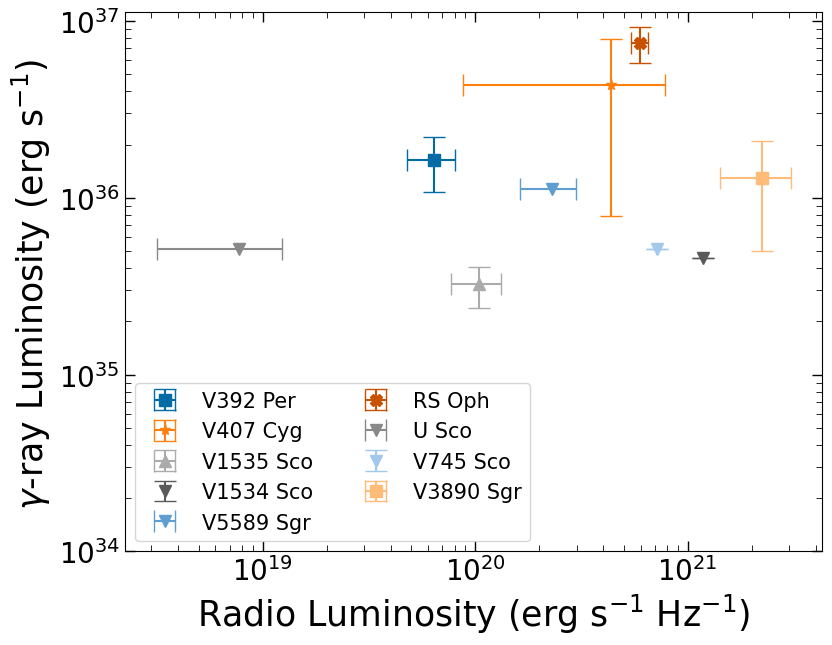

In [54]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.errorbar(Lum[0], Per_Lum, yerr=Per_Lum_err[0], xerr = er1[0], label="V392 Per", fmt='s',capsize=8, markersize=8)

ax.errorbar(Lum[1], Cyg_Lum, yerr=Cyg_Lum_err[0], xerr = er2[0], label="V407 Cyg",  fmt='*',capsize=8, markersize=8)

ax.errorbar(Lum[2], Sco35_Lum, yerr=Sco35_Lum_err[0], xerr = er3[0], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.errorbar(Lum[3],  Sco34_Lum,  yerr = er4[0], fmt='v', label="V1534 Sco", capsize=8, markersize=8)            

ax.errorbar(Lum[5], Sgr_Lum, xerr =  er6[0], label="V5589 Sgr", fmt='v', capsize=8, markersize=8)

ax.errorbar(Lum[6], RS_Lum, yerr=RS_Lum_err[0],  xerr =  er7[0], label="RS Oph", fmt='X', capsize=8, markersize=8)

ax.errorbar(Lum[7],  U_Lum, xerr =  er8[0],  label="U Sco", fmt='v', capsize=8, markersize=8)

ax.errorbar(Lum[8], Sco_Lum, yerr =  er9[0], label="V745 Sco", fmt='v', capsize=8, markersize=8)

ax.errorbar(Lum[9], V_Lum, yerr=V_Lum_err, xerr=er10[0], label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.set_yscale('log')
ax.set_xscale('log')

ax.set_yticks([1e34, 1e35, 1e36, 1e37], labels = [r'$10^{34}$',r'$10^{35}$', r'$10^{36}$', r'$10^{37}$'], fontsize = 20)
ax.set_xticks([1e19, 1e20, 1e21], labels = [r'$10^{19}$',r'$10^{20}$', r'$10^{21}$'], fontsize = 20)

ax.set_ylabel(r"$\gamma$-ray Luminosity (erg s$^{-1}$) ", fontsize=25)
ax.set_xlabel(r"Radio Luminosity (erg s$^{-1}$ Hz$^{-1}$)", fontsize=25)


ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)

plt.legend(fontsize = 15, loc='lower left', ncol=2)
plt.show()
fig.savefig("Rad_Gam_Lum", dpi=300);

## Gamma ray L vs Orbital Period 
- Plot: Gamma ray luminosity vs orbital period in hours
- Scale: log-log
- Notes:

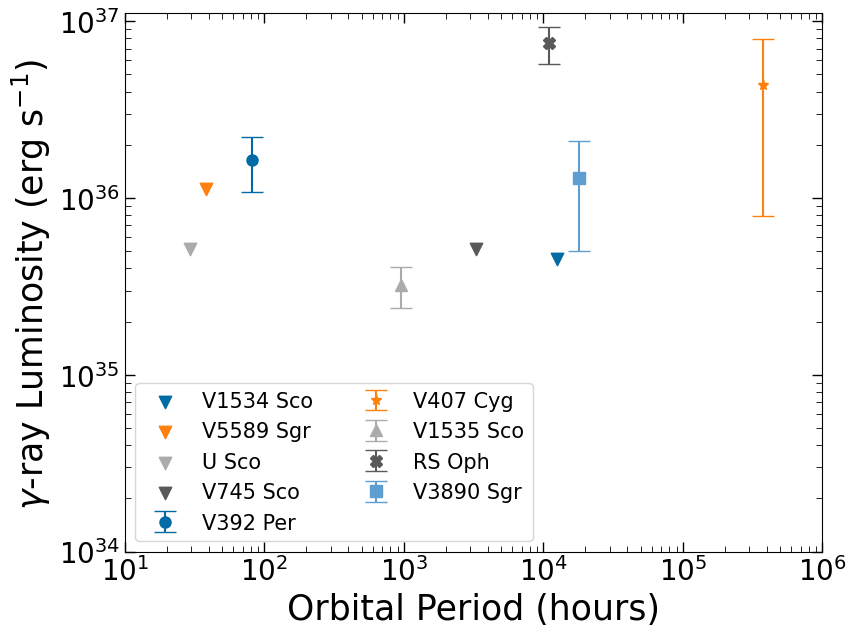

In [55]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.errorbar(Orb[0], Per_Lum, yerr=Per_Lum_err[0],  label="V392 Per", fmt='o',capsize=8, markersize=8)

ax.errorbar(Orb[1], Cyg_Lum,  yerr=Cyg_Lum_err[0], label="V407 Cyg",  fmt='*',capsize=8, markersize=8)

ax.errorbar(Orb[2], Sco35_Lum, yerr=Sco35_Lum_err[0], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.scatter(Orb[3], Sco34_Lum, marker='v', label="V1534 Sco", s=80)            

ax.scatter(Orb[5],Sgr_Lum, label="V5589 Sgr", marker='v', s=80)

ax.errorbar(Orb[6], RS_Lum, yerr=RS_Lum_err[0], label="RS Oph", fmt='X', capsize=8, markersize=8)

ax.scatter(Orb[7], U_Lum, marker='v', label="U Sco", s=80)

ax.scatter(Orb[8],Sco_Lum, label="V745 Sco", marker='v', s=80)

ax.errorbar(Orb[9], V_Lum, yerr=V_Lum_err, label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.set_yscale('log')
ax.set_xscale('log')

ax.set_yticks([1e34, 1e35, 1e36, 1e37], labels = [r'$10^{34}$',r'$10^{35}$', r'$10^{36}$', r'$10^{37}$'], fontsize = 20)
ax.set_xticks([10, 100, 1000, 10000, 100000, 1000000], labels = [r'$10^1$', r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$', r'$10^6$'], fontsize = 20)

ax.set_ylabel(r"$\gamma$-ray Luminosity (erg s$^{-1}$) ", fontsize=25)
ax.set_xlabel("Orbital Period (hours)", fontsize=25)

ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)

ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
#ax.xaxis.set_minor_locator(AutoMinorLocator(5))

plt.legend(loc="lower left", fontsize=15, ncol=2)
plt.show()
fig.savefig("Orb_Gam_Lum", dpi=300);